# MobAI — Warehouse Optimisation: placement, slotting and multi-trolley routing

Three linked decisions for warehouse **B7**, built on the real location master and two years of real order
history from the hackathon data pack:

| Module | Decision | Method |
|---|---|---|
| **A. Inbound placement** | which reserve slot gets each incoming pallet | weighted score → greedy rule vs **exact assignment (Hungarian)** |
| **B. Pick-face slotting** | which product sits at which picking position | frequency-based slotting (provably optimal for this cost) |
| **C. Routing** | how several picking trolleys move without colliding | **A\* in space-time with reservations** (prioritised planning) |

> **Layout note.** The data gives location *codes*, not coordinates. Codes are decoded
> (picking `<level><row>-<bay>-<pos>`, reserve `B07-N<floor>-<row><slot>`) and placed on a schematic grid
> (1 cell ≈ 1 m): back-to-back rack rows, one-way-wide aisles, cross aisles at both ends, expedition dock
> bottom-left, reception top-right, elevator bottom-right. Distances are in grid steps.
> All logic lives in `mobai_opt.py`.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, warnings
warnings.filterwarnings('ignore'); plt.rcParams['figure.dpi'] = 110
from mobai_opt import *
X = 'WMS_Hackathon_DataPack_Templates_FR_FV_B7_ONLY.xlsx'

L = parse_locations(pd.read_excel(X, sheet_name='emplacements'))
grid = build_grid()
print(L.kind.value_counts().to_string())
print('reserve slots per floor:', L[L.kind == 'RESERVE'].floor.value_counts().sort_index().to_dict())

d = pd.read_excel(X, sheet_name='historique_demande')
d['ts'] = pd.to_datetime(d.date); d['day'] = d.ts.dt.normalize()
p = pd.read_excel(X, sheet_name='produits').iloc[2:].copy()
p.columns = ['id_produit','sku','nom','um','cat','actif','fardeau','palette','vol','poids','gerb']
p['id_produit'] = pd.to_numeric(p.id_produit, errors='coerce')
for c in ['fardeau', 'palette', 'vol']: p[c] = pd.to_numeric(p[c], errors='coerce')
p = p.set_index('id_produit')
ndays = d.day.nunique(); nweeks = ndays / 6          # 6 working days a week (Friday closed)
agg = d.groupby('id_produit').agg(qty=('quantite_demande', 'sum'), lines=('quantite_demande', 'size'))
agg['pal'] = agg.index.map(p.palette); agg['pal'] = agg.pal.where(agg.pal > 0, agg.pal.median())
agg['pallets_week'] = agg.qty / agg.pal / nweeks                   # pallet movements per week
agg['pallet_m3'] = (agg.index.map(p.vol) * agg.pal).fillna(0)      # weight column is empty -> pallet volume as proxy
print(f'{ndays} working days, {len(agg)} products ordered')

kind
PICK       660
RESERVE    167
reserve slots per floor: {1: 52, 2: 52, 3: 27, 4: 36}


598 working days, 1129 products ordered


## A — Inbound placement (receipt → reserve)

Each pallet `p` going to slot `c` costs

$$\text{score}(p,c) = f_p\,(\alpha\,\hat d_{exp}(c) + \beta\,\hat d_{rec}(c) + \gamma\,\hat d_{elev}(c)) + \delta\,\text{bulk}_p\cdot \text{floor}(c)$$

`f_p` = how often the pallet moves (weekly pallet movements, from demand), `d̂` = normalised distances
(upper floors are reached through the elevator), `bulk` = pallet-volume rank (weights are empty in the data,
so volume is the proxy for "heavy, keep low"). α=1, β=0.2, γ=0.3, δ=0.5.

One pallet per fast-moving product competes for the reserve slots. Four strategies:
- **random** free slot (no system),
- **greedy, arrival order**: each pallet takes its best free slot as it arrives,
- **greedy, fastest first**: same rule, but the day's receipts are sorted by turnover first,
- **optimal**: the assignment problem solved exactly with the Hungarian algorithm (`scipy.linear_sum_assignment`).

In [2]:
R = reserve_distances(L); n = len(R)
P = agg.sort_values('qty', ascending=False).head(n).copy()
P['freq'] = P.pallets_week / P.pallets_week.max()
P['bulk'] = P.pallet_m3.rank(pct=True)
Cm = placement_cost_matrix(P, R)

rng = np.random.default_rng(0)
strategies = {
    'random':                [assign_random(Cm, s) for s in range(30)],
    'greedy, arrival order': [assign_greedy(Cm, np.random.default_rng(s).permutation(n)) for s in range(30)],
    'greedy, fastest first': [assign_greedy(Cm, np.argsort(-P.freq.values))],
    'optimal (Hungarian)':   [assign_optimal(Cm)],
}
def metrics(a):
    return dict(score=Cm[np.arange(n), a].sum(),
                travel=(P.pallets_week.values * 2 * R.d_exp.values[a]).sum(),   # round trips to expedition / week
                bulky_floor=(P.bulk.values * R.floor.values[a]).sum() / P.bulk.sum())
A = pd.DataFrame({k: pd.DataFrame([metrics(a) for a in v]).mean() for k, v in strategies.items()}).T
A['travel vs random'] = A.travel / A.loc['random', 'travel'] - 1
A['score vs random'] = A.score / A.loc['random', 'score'] - 1
print(A.round(3).to_string())

                        score     travel  bulky_floor  travel vs random  score vs random
random                 34.430  29561.481        2.281             0.000            0.000
greedy, arrival order  33.016  28879.934        2.238            -0.023           -0.041
greedy, fastest first  29.708  21320.792        2.371            -0.279           -0.137
optimal (Hungarian)    23.396  22732.239        1.727            -0.231           -0.320


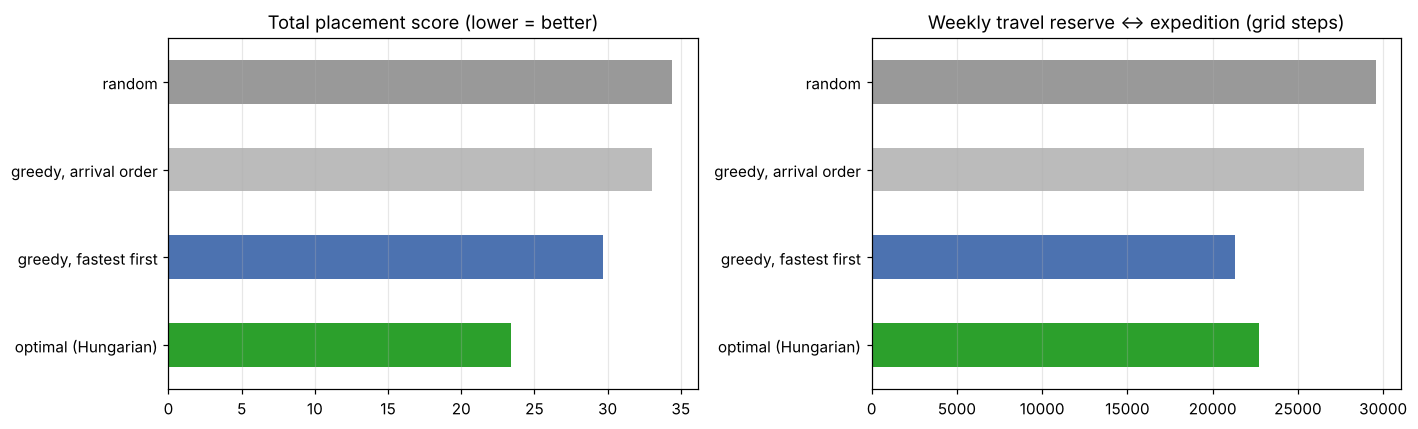

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
A.score.plot(kind='barh', ax=ax[0], color=['#999', '#bbb', '#4c72b0', '#2ca02c']); ax[0].invert_yaxis()
ax[0].set_title('Total placement score (lower = better)'); ax[0].grid(alpha=.3, axis='x')
A.travel.plot(kind='barh', ax=ax[1], color=['#999', '#bbb', '#4c72b0', '#2ca02c']); ax[1].invert_yaxis()
ax[1].set_title('Weekly travel reserve ↔ expedition (grid steps)'); ax[1].grid(alpha=.3, axis='x')
plt.tight_layout(); plt.show()

**Reading it.** Without sorting, the greedy rule barely beats random: early pallets grab the best slots
whatever their turnover. Sorting receipts by turnover is enough to cut travel sharply. The exact assignment
gives the best total score; it gives up a little travel to keep bulky pallets on low floors (lowest
"bulky floor" value), which is exactly the trade-off the weights encode.

## B — Pick-face slotting

The 660 picking positions differ in walking distance from the expedition dock and in rack level (higher
levels take longer to reach). Cost per order line at slot *s* = 2 × distance + 3 × level.
For a sum of *frequency × slot cost*, giving the most frequent product the cheapest slot is optimal
(rearrangement inequality), so no solver is needed.

products slotted: 660 (they carry 99.3% of all order lines)
daily picking travel  random: 11,416  | frequency slotting: 5,732  (-49.8%)


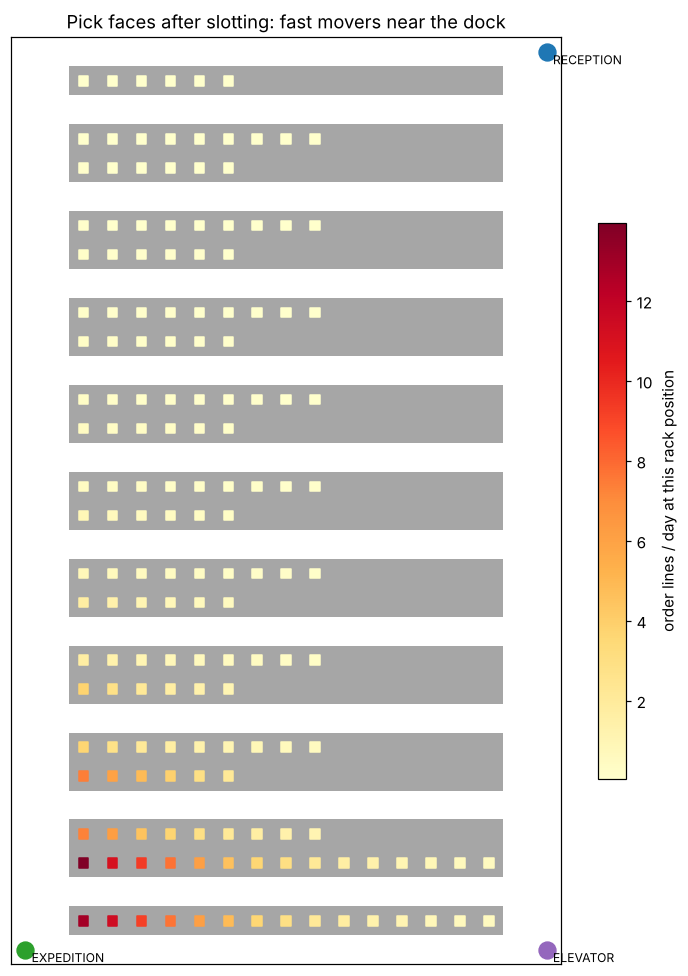

In [4]:
PK = L[L.kind == 'PICK'].reset_index(drop=True)
cost = pick_cost(L).values; m = len(cost)
S = agg.sort_values('lines', ascending=False).head(m)
lpd = S.lines.values / ndays                                     # order lines per working day
slot = slot_by_frequency(lpd, cost)
rand = np.mean([(lpd * cost[np.random.default_rng(s).permutation(m)]).sum() for s in range(30)])
opt = (lpd * cost[slot]).sum()
print(f'products slotted: {m} (they carry {S.lines.sum() / agg.lines.sum():.1%} of all order lines)')
print(f'daily picking travel  random: {rand:,.0f}  | frequency slotting: {opt:,.0f}  ({opt / rand - 1:+.1%})')

fig, ax = plt.subplots(figsize=(7, 9))
ax.imshow(grid, cmap='Greys', alpha=.35, origin='upper')
heat = pd.DataFrame({'x': PK.x.values[slot], 'y': PK.rack_y.values[slot], 'f': lpd}).groupby(['x', 'y']).f.sum().reset_index()
sc = ax.scatter(heat.x, heat.y, c=heat.f, s=38, marker='s', cmap='YlOrRd')
for nm, (x, y), c in [('EXPEDITION', EXPEDITION, 'tab:green'), ('RECEPTION', RECEPTION, 'tab:blue'), ('ELEVATOR', ELEVATOR, 'tab:purple')]:
    ax.plot(x, y, 'o', ms=11, color=c); ax.annotate(nm, (x, y), xytext=(4, -8), textcoords='offset points', fontsize=8)
plt.colorbar(sc, ax=ax, shrink=.6, label='order lines / day at this rack position')
ax.set_title('Pick faces after slotting: fast movers near the dock'); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## C — Multi-trolley routing with space-time reservations

Replay the busiest real day: its first 16 orders are released two time steps apart, one trolley per order.
Each trolley visits the pick faces of its order (nearest-neighbour sequence) and returns to the dock.

- **Independent A\***: every trolley takes its own shortest path, ignoring the others.
- **Cooperative A\***: trolleys plan in release order; each plan reserves its `(cell, time)` cells and
  edges, and later trolleys search in space-time (with a *wait* action) around those reservations.
  Collisions and head-on swaps in aisles become impossible by construction.

In [5]:
face = {sku: (int(PK.x[j]), int(PK.y[j])) for sku, j in zip(S.index, slot)}
busy = d.groupby('day').ts.nunique().idxmax()
orders = [g.id_produit.tolist() for _, g in d[d.day == busy].groupby('ts')][:16]
tours_nn = [tour_order([face[s] for s in o if s in face], EXPEDITION) for o in orders]
tours_seq = [list(dict.fromkeys(face[s] for s in o if s in face)) + [EXPEDITION] for o in orders]
starts = [(EXPEDITION, 2 * i) for i in range(len(orders))]
dock = {EXPEDITION}
print(f'busiest day: {busy.date()} | orders replayed: {len(orders)} | pick lines: {sum(len(t) - 1 for t in tours_nn)}')

runs = {
    'independent, order-line sequence': plan_fleet(grid, tours_seq, starts, cooperative=False, free_cells=dock),
    'independent, nearest-neighbour':   plan_fleet(grid, tours_nn, starts, cooperative=False, free_cells=dock),
    'cooperative (reservations)':       plan_fleet(grid, tours_nn, starts, cooperative=True, free_cells=dock),
}
def valid(paths):
    for _, pth in paths:
        for a, b in zip(pth, pth[1:]):
            assert manhattan(a, b) <= 1 and grid[b[1], b[0]] == 0
    return True
T = pd.DataFrame({k: {**path_stats(v), 'collisions': count_conflicts(v, dock), 'paths valid': valid(v)} for k, v in runs.items()}).T
print(T.to_string())

busiest day: 2024-11-10 | orders replayed: 16 | pick lines: 111


                                 time_steps waits makespan collisions paths valid
independent, order-line sequence       1048     0      154        201        True
independent, nearest-neighbour          746     0      122        127        True
cooperative (reservations)             1180    84      184          0        True


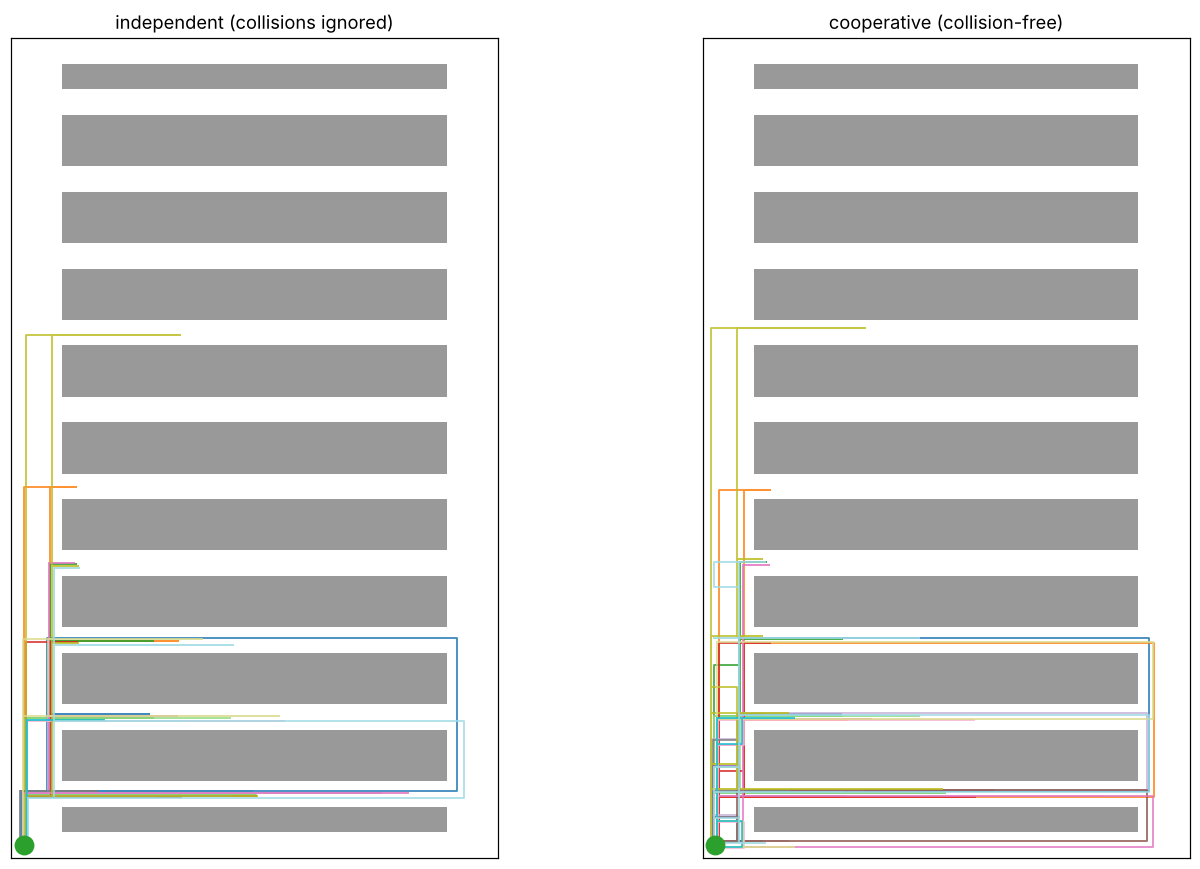

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 8))
for k, (name, paths) in enumerate([('independent (collisions ignored)', runs['independent, nearest-neighbour']),
                                   ('cooperative (collision-free)', runs['cooperative (reservations)'])]):
    ax[k].imshow(grid, cmap='Greys', alpha=.4, origin='upper')
    cm = plt.cm.tab20(np.linspace(0, 1, len(paths)))
    for c, (_, pth) in zip(cm, paths):
        xs, ys = zip(*pth); jitter = (np.random.default_rng(len(pth)).random() - .5) * .35
        ax[k].plot(np.array(xs) + jitter, np.array(ys) + jitter, '-', lw=1.2, color=c, alpha=.85)
    ax[k].plot(*EXPEDITION, 'o', ms=12, color='tab:green')
    ax[k].set_title(name); ax[k].set_xticks([]); ax[k].set_yticks([])
plt.tight_layout(); plt.show()

**Reading it.** Planning each trolley alone looks fastest on paper, but the plan contains dozens of
collisions and head-on meetings in one-trolley-wide aisles, so it cannot be executed. The reservation
planner removes every conflict; the price is the extra time shown in the table (waits plus small detours),
which is the real cost of congestion on a busy day. Ordering picks by nearest neighbour instead of the
order-line sequence also shortens every tour.

## How the modules connect

```
weekly demand forecast  →  turnover per product  →  A. where to store pallets
                                                 →  B. which pick face each product gets
next-day preparation orders  →  C. trolley tours + collision-free routes
```

**Limits.** Geometry is schematic, pallet weights are missing (volume used instead), and the routing
uses prioritised planning, which is fast and conflict-free but not globally optimal (CBS would be the
next step for small fleets).